In [1]:
import sys

sys.path.append("..")

from analysis.utils import get_runs_data, show_config_differences
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style(style="darkgrid")

data = get_runs_data(
    tag="higher-vocab",
    project="memorization",
    metrics=[
        "train/exact_match_repeated",
    ],
)
show_config_differences(data)

Found 12 runs with tag 'higher-vocab'


,cfg.dataset.npz_path,cfg.training.batch_size,cfg.dataset_metadata.strategy,cfg.dataset_metadata.num_samples,cfg.dataset_metadata.target_level
_run_id,,,,,
56s9x9j7,datasets/level_2a_aggregation_formula_strategy...,512,lookback,20000,2a
6313hb68,datasets/level_2a_aggregation_formula_strategy...,512,random,20000,2a
6gjz66fl,datasets/level_2a_aggregation_formula_strategy...,512,lookback,15000,2a
71wp49mr,datasets/level_2a_aggregation_formula_strategy...,256,lookback,10000,2a
gmj8paty,datasets/level_0_aggregation_formula_seed_0.npz,512,None,20000,0
is1j7oer,datasets/level_1_aggregation_formula_global_po...,512,None,20000,1
ju8565vb,datasets/level_2a_aggregation_formula_strategy...,256,random,10000,2a
klqh0pkc,datasets/level_2a_aggregation_formula_strategy...,512,random,15000,2a
pw589wgb,datasets/level_0_aggregation_formula_seed_0.npz,512,None,15000,0


In [2]:
data.columns

Index(['train/exact_match_repeated', 'train/global_step', '_run_id',
       '_run_name', 'cfg.dataset._target_', 'cfg.dataset.npz_path',
       'cfg.model.n_embd', 'cfg.model.n_head', 'cfg.model.n_layer',
       'cfg.model.freeze_embeddings', 'cfg.training.bf16', 'cfg.training.seed',
       'cfg.training.optim', 'cfg.training.max_steps',
       'cfg.training.report_to', 'cfg.training.batch_size',
       'cfg.training.save_steps', 'cfg.training.warmup_steps',
       'cfg.training.weight_decay', 'cfg.training.learning_rate',
       'cfg.training.logging_steps', 'cfg.training.max_grad_norm',
       'cfg.training.loss_logging_mode', 'cfg.training.lr_scheduler_type',
       'cfg.training.dataloader_pin_memory',
       'cfg.training.ignore_pad_tokens_in_loss',
       'cfg.training.gradient_accumulation_steps', 'cfg.dataset_metadata.seed',
       'cfg.dataset_metadata.seq_len', 'cfg.dataset_metadata.lookback',
       'cfg.dataset_metadata.strategy', 'cfg.dataset_metadata.pos',
       'cfg.dat

In [3]:
data["cfg.dataset_metadata.aggregation"].unique()

array(['formula'], dtype=object)

In [4]:
data["cfg.dataset_metadata.vocab_size"].unique()

array([10000])

In [11]:
LEVEL_COL = "cfg.dataset_metadata.target_level"
STRATEGY_COL = "cfg.dataset_metadata.strategy"
METRIC_NAME = "train/exact_match_repeated"
SEED_COL = "cfg.dataset_metadata.seed"
STEP_COL = "train/global_step"
NUM_SAMPLES_COL = "cfg.dataset_metadata.num_samples"
VOCAB_SIZE_COL = "cfg.dataset_metadata.vocab_size"
MAX_STEP = 8000


def plot_runs(num_samples):
    filtered_data = data[data[NUM_SAMPLES_COL] == num_samples]
    filtered_data = filtered_data[filtered_data[STEP_COL] <= MAX_STEP]

    # Aggregate by level, strategy, aggregation, and step (across seeds)
    groups = (
        filtered_data.groupby(
            [LEVEL_COL, STRATEGY_COL, STEP_COL, VOCAB_SIZE_COL], dropna=False
        )[METRIC_NAME]
        .agg(["mean", "std"])
        .reset_index()
    )

    # Plot each (level, strategy, aggregation) combination
    plt.figure(figsize=(10, 6))
    for (level, strategy, vocab_size), g in groups.groupby(
        [LEVEL_COL, STRATEGY_COL, VOCAB_SIZE_COL], dropna=False
    ):
        label = f"Level {level}"
        if level == "2a":
            label += f" - {strategy}"

        steps = g[STEP_COL]
        mean = g["mean"]
        std = g["std"].fillna(0)  # Handle single-seed cases

        plt.plot(steps, mean, label=label)
        plt.fill_between(
            steps, (mean - std).clip(0, 1), (mean + std).clip(0, 1), alpha=0.2
        )

    plt.xlabel("Training Steps", fontsize=16)
    plt.ylabel("Exact Match", fontsize=16)
    plt.legend(loc="lower center", bbox_to_anchor=(0.5, -0.3), ncol=2, fontsize=14)
    plt.xticks(fontsize=14)
    plt.yticks(fontsize=14)
    plt.title(
        f"Experiments with {num_samples} samples and vocab size {vocab_size}",
        fontsize=18,
    )
    plt.savefig(f"plots/{num_samples}_samples_vocab_{vocab_size}.pdf", bbox_inches="tight")

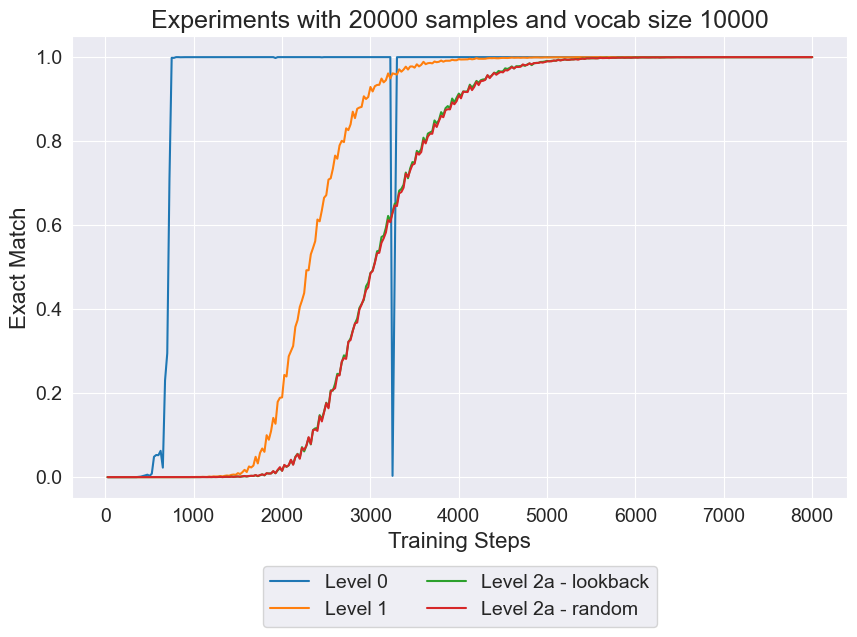

In [12]:
plot_runs(num_samples=20000)

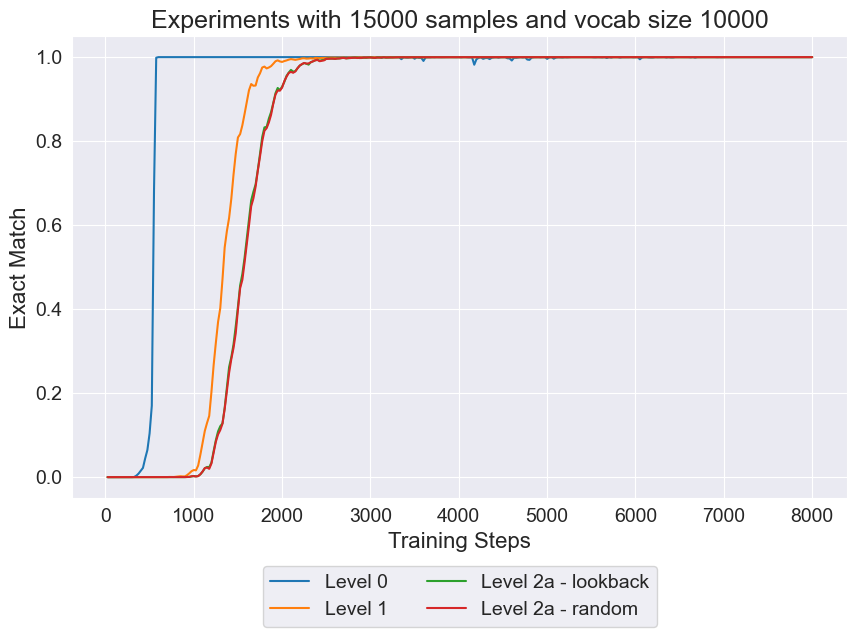

In [13]:
plot_runs(num_samples=15000)